### Task 1: Designing a Heuristic for a Warehouse Robot

In [ ]:
import math
import networkx as nx
import matplotlib.pyplot as plt


# 1. Coordinates of warehouse locations

locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}


# 2. Weighted warehouse graph

warehouse_graph = {
    "Receiving_Area": {
        "Storage_A": 2.2,
        "Storage_B": 4.1
    },

    "Storage_A": {
        "Sorting_Area": 2.2
    },

    "Storage_B": {
        "Inspection_Area": 5.0,
        "Sorting_Area": 6.0
    },

    "Sorting_Area": {
        "Inspection_Area": 3.4,
        "Packing_Station": 5.6
    },

    "Inspection_Area": {
        "Packing_Station": 2.2
    },

    "Packing_Station": {}
}


# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.hypot(x1 - x2, y1 - y2)



# 4. Calculate heuristic values

goal = "Packing_Station"

print("Heuristic Values")
print("----------------")

for location in locations:
    print(f"{location}: {heuristic(location, goal):.2f}")


Heuristic Values
----------------
Receiving_Area: 9.22
Storage_A: 7.07
Storage_B: 6.32
Sorting_Area: 5.00
Inspection_Area: 2.24
Packing_Station: 0.00


#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, you are supposed highlight the actual minimum-cost path merely for visualization:


Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 10.00


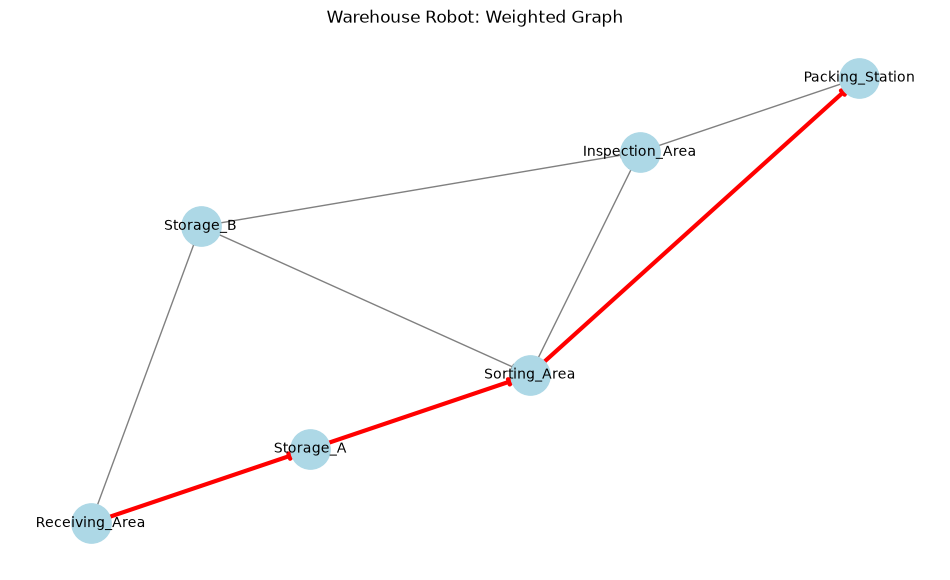

In [41]:
# 5. Create NetworkX graph

G = nx.DiGraph()

for node, neighbors in warehouse_graph.items():
    G.add_node(node, pos=warehouse_locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 6. Find minimum-cost path with Dijkstra's algorithm
source = "Receiving_Area"
target = "Packing_Station"

frontier = [(0.0, source)]
distances = {source: 0.0}
came_from = {source: None}

while frontier:
    current_cost, current = heapq.heappop(frontier)

    if current_cost != distances[current]:
        continue

    if current == target:
        break

    for neighbor, edge_cost in warehouse_graph[current].items():
        new_cost = current_cost + edge_cost
        if new_cost < distances.get(neighbor, float("inf")):
            distances[neighbor] = new_cost
            came_from[neighbor] = current
            heapq.heappush(frontier, (new_cost, neighbor))

if target not in distances:
    raise ValueError(f"No path exists from {source} to {target}")

solution_path = []
current = target
while current is not None:
    solution_path.append(current)
    current = came_from[current]
solution_path.reverse()
solution_cost = distances[target]

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")

# 7. Visualize graph
pos = {node: coords for node, coords in warehouse_locations.items()}

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True)

path_edges = [(solution_path[i], solution_path[i + 1]) for i in range(len(solution_path) - 1)]
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True)

plt.title("Warehouse Robot: Weighted Graph")
plt.axis("off")
plt.show()


In [42]:
# 8. Verify heuristic condition

print("\nHeuristic Condition Verification")
print("*********************************")

for node in warehouse_graph:
    for neighbor, cost in warehouse_graph[node].items():
        h_node = heuristic(node, goal)
        h_neighbor = heuristic(neighbor, goal)

        if h_node <= cost + h_neighbor:
            print(f"{node} -> {neighbor}: OK")
        else:
            print(f"Violation: h({node})={h_node:.2f} > {cost:.2f} + h({neighbor})={h_neighbor:.2f}")



Heuristic Condition Verification
*********************************
Receiving_Area -> Storage_A: OK
Receiving_Area -> Storage_B: OK
Storage_A -> Sorting_Area: OK
Storage_B -> Inspection_Area: OK
Storage_B -> Sorting_Area: OK
Sorting_Area -> Inspection_Area: OK
Sorting_Area -> Packing_Station: OK
Violation: h(Inspection_Area)=2.24 > 2.20 + h(Packing_Station)=0.00


Observation: The Euclidean heuristic is not admissible for this graph because it overestimates the true remaining cost on the edge Inspection_Area -> Packing_Station: h(Inspection_Area) = 2.24 > 2.20 + h(Packing_Station) = 2.20.


### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [43]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates

airport_locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (6, 4),
    "Departure_Gate": (8, 5)
}

# 2. Weighted graph

airport_graph = {
    "Baggage_Area": {
        "Security": 2.2,
        "Checkpoint": 4.1
    },

    "Security": {
        "Food_Court": 2.2
    },

    "Checkpoint": {
        "Terminal_Hall": 5.0
    },

    "Food_Court": {
        "Terminal_Hall": 3.2,
        "Departure_Gate": 6.0
    },

    "Terminal_Hall": {
        "Departure_Gate": 3.2
    },

    "Departure_Gate": {}
}

# 3. Euclidean heuristic


def heuristic(current, goal):
    x1, y1 = airport_locations[current]
    x2, y2 = airport_locations[goal]
    return math.hypot(x1 - x2, y1 - y2)


# 4. GBFS

def greedy_best_first_search(start, goal, graph):
    open_heap = [(heuristic(start, goal), start)]
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, cost in graph[current].items():
            if neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(open_heap, (heuristic(neighbor, goal), neighbor))

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()
    total_cost = 0.0

    for i in range(len(path) - 1):
        total_cost += graph[path[i]][path[i + 1]]

    return expansion_order, path, total_cost


# 5. Run GBFS

start = "Baggage_Area"
goal = "Departure_Gate"
expansion_order, path, total_cost = greedy_best_first_search(start, goal, airport_graph)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")


GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30


#### NetworkX visualization

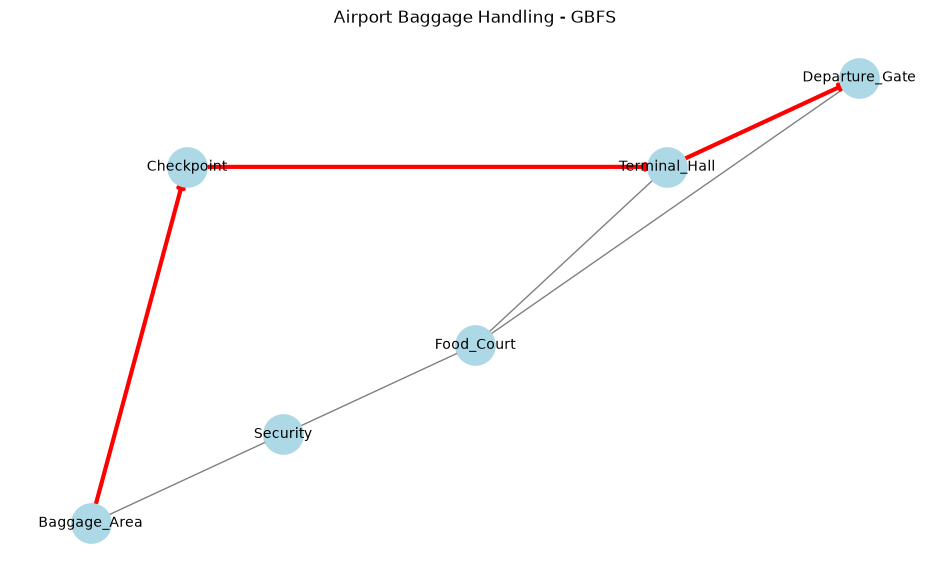

In [44]:
# 6. NetworkX visualization

G = nx.DiGraph()

for node, neighbors in airport_graph.items():
    G.add_node(node, pos=airport_locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = airport_locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True)

path_edges = [(path[i], path[i + 1]) for i in range(len(path) - 1)]
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True)

plt.title("Airport Baggage Handling - GBFS")
plt.axis("off")
plt.show()


### Task 3: A* Search for Emergency Supply Robot

In [45]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt


# 1. Hospital coordinates

hospital_locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}


# 2. Hospital weighted graph

hospital_graph = {
    "Pharmacy": {
        "Main_Corridor": 2.2,
        "Patient_Wing": 4.1
    },

    "Main_Corridor": {
        "Nursing_Station": 2.2
    },

    "Patient_Wing": {
        "Laboratory": 5.0
    },

    "Nursing_Station": {
        "Laboratory": 3.4,
        "Emergency_Ward": 5.0
    },

    "Laboratory": {
        "Emergency_Ward": 2.2
    },

    "Emergency_Ward": {}
}

# 3. Euclidean heuristic

def heuristic(current, goal):
    x1, y1 = hospital_locations[current]
    x2, y2 = hospital_locations[goal]
    return math.hypot(x1 - x2, y1 - y2)


# 4. Path reconstruction

def reconstruct_path(came_from, current):
    path = []
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()
    return path


# 5. A* Search
def a_star_search(start, goal, graph):
    global g_cost

    open_heap = [(heuristic(start, goal), 0.0, start)]
    came_from = {start: None}
    g_cost = {start: 0.0}
    expansion_order = []
    visited = set()

    while open_heap:
        _, current_cost, current = heapq.heappop(open_heap)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, edge_cost in graph[current].items():
            tentative_g = current_cost + edge_cost
            if tentative_g < g_cost.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                f_cost = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_heap, (f_cost, tentative_g, neighbor))

    path = reconstruct_path(came_from, goal)
    total_cost = g_cost[goal]
    return expansion_order, path, total_cost


# 6. Run A*
start = "Pharmacy"
goal = "Emergency_Ward"
expansion_order, path, total_cost = a_star_search(start, goal, hospital_graph)

print("A* Search")
print("--------------------------------")

print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 9.40


#### g(n), h(n), f(n) table

In [46]:
# you may also replace it with dataframe it is completely your own choice

print("\nA* Node Information")
print("*********************")
print(
    f"{'Node':20s}"
    f"{'g(n)':>10s}"
    f"{'h(n)':>10s}"
    f"{'f(n)':>10s}"
)

for node in expansion_order:
    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h

    print(
        f"{node:20s}"
        f"{g:10.2f}"
        f"{h:10.2f}"
        f"{f:10.2f}"
    )


A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward            9.40      0.00      9.40


#### NetworkX visualization

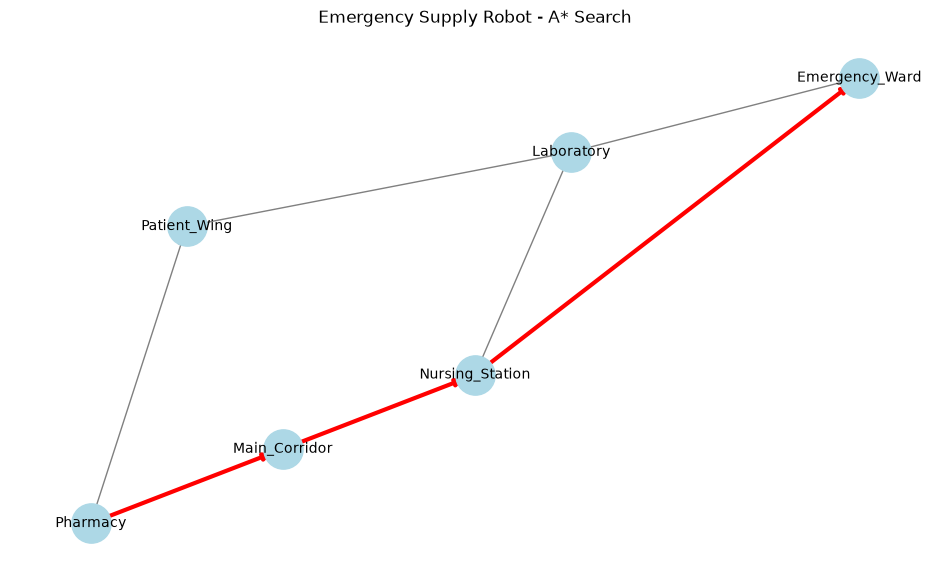

In [47]:
# 7. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in hospital_graph.items():
    G.add_node(node, pos=hospital_locations[node])
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = hospital_locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=800)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True)

path_edges = [(path[i], path[i + 1]) for i in range(len(path) - 1)]
nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True)

plt.title("Emergency Supply Robot - A* Search")
plt.axis("off")
plt.show()

GBFS would primarily ask:

"Which node appears closest to the Emergency Ward?"

A* instead asks:

"Considering both the cost already travelled and the estimated remaining cost, which node has the lowest estimated total cost?"

### Task 4: Weighted A* for Autonomous Delivery Drone

In [ ]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates

locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (7, 6)
}

# 2. Weighted Graph

graph = {
    "Distribution_Center": {
        "Zone_A": 2.2,
        "Zone_B": 3.0
    },

    "Zone_A": {
        "Zone_C": 2.2
    },

    "Zone_B": {
        "Zone_D": 5.0
    },

    "Zone_C": {
        "Customer_Building": 6.0
    },

    "Zone_D": {
        "Customer_Building": 3.2
    },

    "Customer_Building": {}
}

# 3. Euclidean Heuristic

def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.hypot(x1 - x2, y1 - y2)

# 4. Display Heuristic Values
goal = "Customer_Building"

heuristic_data = []

for node in locations:
    heuristic_data.append({
        "Node": node,
        "h(n)": round(heuristic(node, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

# 5. Weighted A* Search
# f(n) = g(n) + w * h(n)


def weighted_a_star(start, goal, graph, weight):
    open_heap = [(weight * heuristic(start, goal), 0.0, start)]
    came_from = {start: None}
    g_cost = {start: 0.0}
    expansion_order = []
    visited = set()

    while open_heap:
        _, current_cost, current = heapq.heappop(open_heap)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, edge_cost in graph[current].items():
            tentative_g = current_cost + edge_cost
            if tentative_g < g_cost.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                f_cost = tentative_g + weight * heuristic(neighbor, goal)
                heapq.heappush(open_heap, (f_cost, tentative_g, neighbor))

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = came_from[current]
    path.reverse()

    return path, g_cost[goal], expansion_order

# 6. Run Weighted A* for All Required Weights
start = "Distribution_Center"
goal = "Customer_Building"

weights = [1, 1.5, 2, 3]

results = []

for w in weights:
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)
    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })

# 7. Display Results in dataframe
result_df = pd.DataFrame(results)
print("\nWeighted A* Results:")
print(result_df.to_string(index=False))

# 8. Display Detailed Expansion Orders
print("\nDetailed expansion orders:")
for row in results:
    print(f"w = {row['Weight']}: {row['Expansion Order']}")


# ***
# Expected Main Results
# ***

# w = 1:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 1.5:
# Distribution_Center → Zone_A → Zone_C → Customer_Building
# Cost = 10.4
#
# w = 2:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2
#
# w = 3:
# Distribution_Center → Zone_B → Zone_D → Customer_Building
# Cost = 11.2

Heuristic Values:
               Node  h(n)
Distribution_Center  9.22
             Zone_A  7.07
             Zone_B  6.32
             Zone_C  5.00
             Zone_D  2.24
  Customer_Building  0.00

Weighted A* Results:
 Weight                                             Solution Path  Total Cost  Nodes Expanded                                                             Expansion Order
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               6 Distribution_Center → Zone_A → Zone_B → Zone_C → Zone_D → Customer_Building
    1.5 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4                   Distribution_Center → Zone_B → Zone_D → Customer_Building
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4                   Distribution_Center → Zone_B → Zone_D → Customer_Building
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4     

#### NetworkX visualization

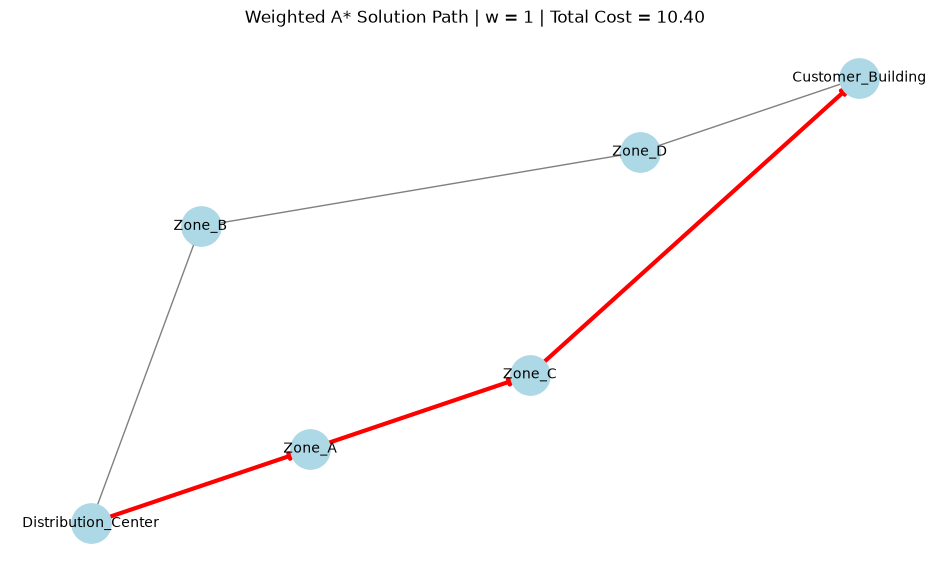

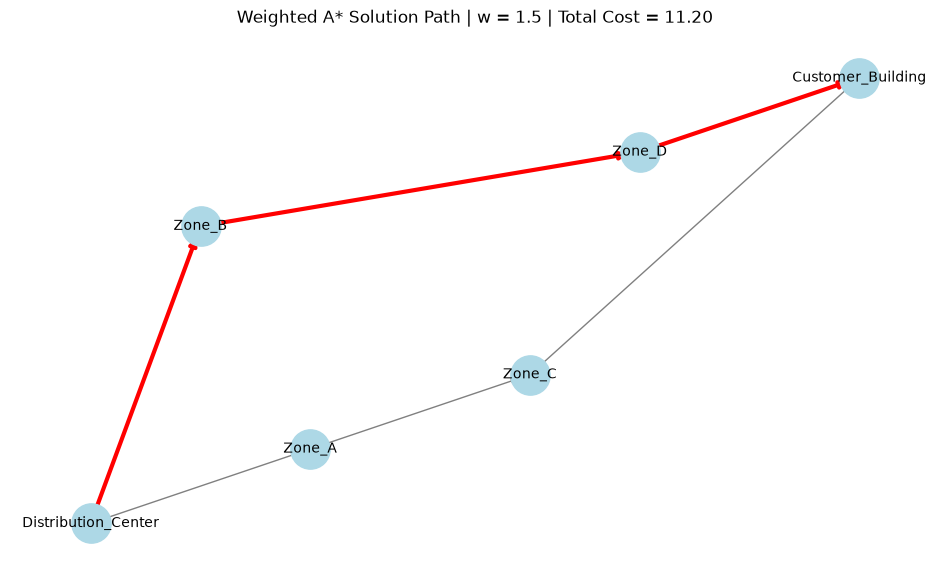

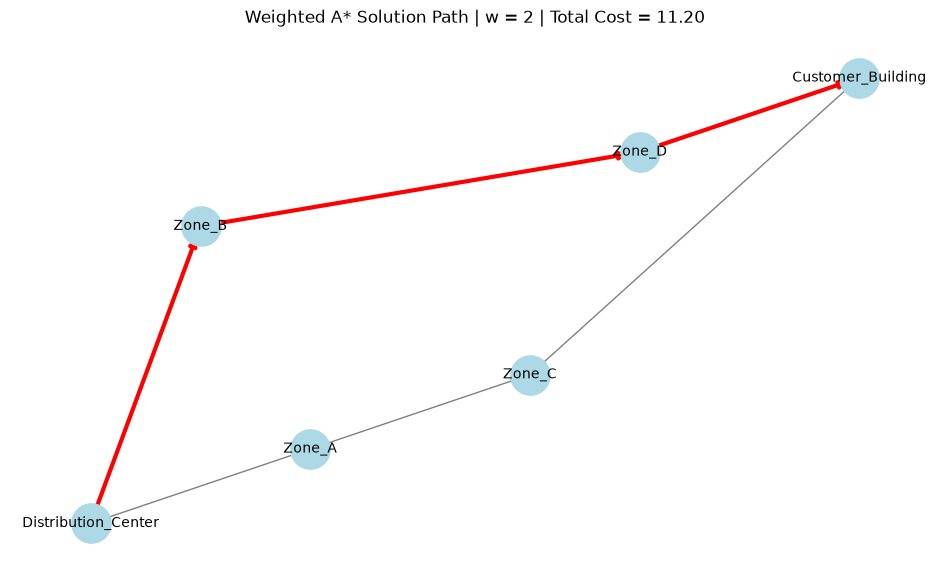

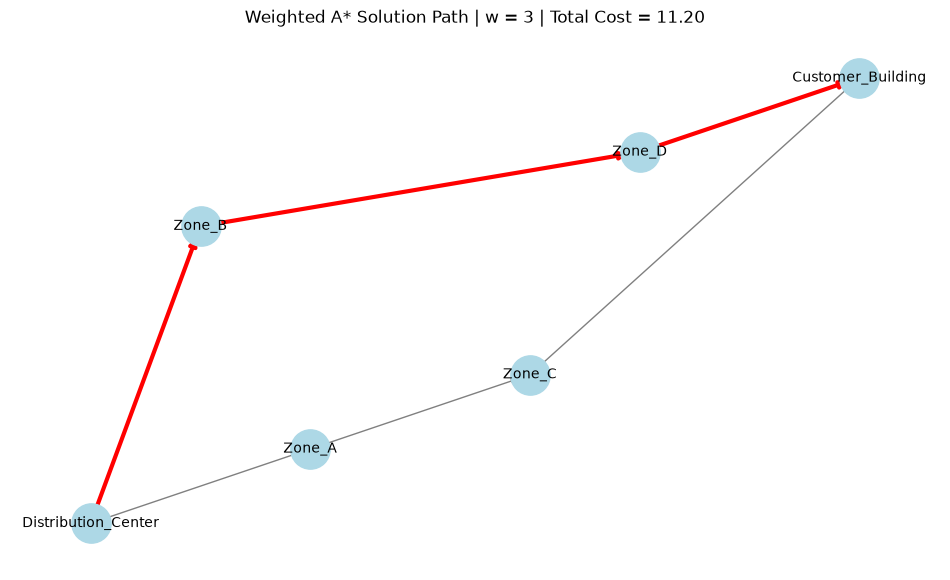

In [51]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create NetworkX Graph

G = nx.DiGraph()

# Add nodes with their coordinates
for node, position in locations.items():
    G.add_node(node, pos=position)

# Add weighted edges
for node, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 2. Node Positions
pos = locations

# 3. Visualize Weighted A* Result for Each Weight
for w in weights:
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)
    path_edges = [(path[i], path[i + 1]) for i in range(len(path) - 1)]

    plt.figure(figsize=(12, 7))
    nx.draw_networkx_nodes(G, pos, node_color="lightblue", node_size=800)
    nx.draw_networkx_labels(G, pos, font_size=10)
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=3, arrows=True)
    plt.title(f"Weighted A* Solution Path | w = {w} | Total Cost = {cost:.2f}")
    plt.axis("off")
    plt.show()